In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("/content/match_closing.csv")

In [3]:
df.head()

,match_id,bookmaker,open_1x2_home,open_1x2_draw,open_1x2_away,close_1x2_home,close_1x2_draw,close_1x2_away,open_ah_line,open_ah_home,...,ah_away_result,open_ou_line,open_ou_over,open_ou_under,close_ou_ts,close_ou_line,close_ou_over,close_ou_under,ou_over_result,ou_under_result
0,1502095,Bet365,2.10,3.30,3.50,2.37,3.75,3.00,0.00,1.70,...,Win Half,2.50,1.98,1.82,2018-09-06T18:42:00Z,2.75,1.98,1.92,Lose,Win
1,1502095,Pinnacle,2.11,3.43,3.56,2.34,3.38,3.11,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1502095,SBOBET,2.11,3.15,3.00,2.34,3.40,2.78,-0.25,1.83,...,Win Half,2.50,2.00,1.82,2018-09-06T18:07:00Z,2.75,2.00,1.90,Lose,Win
3,1502095,Singbet,2.08,3.35,3.10,2.31,3.60,2.91,-0.25,1.82,...,Win Half,2.50,1.97,1.83,2018-09-06T18:43:00Z,2.75,1.95,1.93,Lose,Win
4,1502096,Bet365,1.50,4.33,6.00,1.53,4.20,7.50,-1.00,1.80,...,Push,2.75,1.95,1.85,2018-09-09T18:34:00Z,2.75,2.05,1.85,Win Half,Lose Half


In [4]:
df.tail()

,match_id,bookmaker,open_1x2_home,open_1x2_draw,open_1x2_away,close_1x2_home,close_1x2_draw,close_1x2_away,open_ah_line,open_ah_home,...,ah_away_result,open_ou_line,open_ou_over,open_ou_under,close_ou_ts,close_ou_line,close_ou_over,close_ou_under,ou_over_result,ou_under_result
71623,1918092,Singbet,1.47,4.20,6.10,1.50,3.85,6.50,-1.00,1.85,...,Push,2.50,1.98,1.88,2021-03-05T20:38:00Z,2.25,2.04,1.83,Win,Lose
71624,1918093,Bet365,7.00,4.33,1.44,9.00,4.75,1.33,1.25,1.89,...,Lose Half,2.75,2.03,1.83,2021-03-13T20:11:00Z,2.50,1.88,1.98,Lose,Win
71625,1918093,Pinnacle,6.84,4.17,1.53,9.63,4.96,1.38,1.00,2.00,...,Lose Half,2.50,1.85,2.02,2021-03-13T20:26:00Z,2.50,1.90,1.99,Lose,Win
71626,1918093,SBOBET,6.80,4.40,1.42,9.25,4.80,1.34,1.25,1.90,...,Lose Half,2.75,2.02,1.88,2021-03-13T20:06:00Z,2.50,1.93,1.97,Lose,Win
71627,1918093,Singbet,6.70,4.55,1.41,8.80,4.55,1.34,1.25,1.90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71628 entries, 0 to 71627
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   match_id         71628 non-null  int64  
 1   bookmaker        71628 non-null  object 
 2   open_1x2_home    71409 non-null  float64
 3   open_1x2_draw    71409 non-null  float64
 4   open_1x2_away    71409 non-null  float64
 5   close_1x2_home   71409 non-null  float64
 6   close_1x2_draw   71409 non-null  float64
 7   close_1x2_away   71409 non-null  float64
 8   open_ah_line     69342 non-null  float64
 9   open_ah_home     69342 non-null  float64
 10  open_ah_away     69342 non-null  float64
 11  close_ah_ts      69342 non-null  object 
 12  close_ah_line    69342 non-null  float64
 13  close_ah_home    69342 non-null  float64
 14  close_ah_away    69342 non-null  float64
 15  ah_home_result   69342 non-null  object 
 16  ah_away_result   69341 non-null  object 
 17  open_ou_line

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
match_id,0
bookmaker,0
open_1x2_home,219
open_1x2_draw,219
open_1x2_away,219
close_1x2_home,219
close_1x2_draw,219
close_1x2_away,219
open_ah_line,2286
open_ah_home,2286


In [12]:
df['match_id'] = df['match_id'].fillna(df['match_id'].mean())

In [14]:
df.isnull().sum()

,0
match_id,0
bookmaker,0
open_1x2_home,0
open_1x2_draw,219
open_1x2_away,219
close_1x2_home,219
close_1x2_draw,219
close_1x2_away,219
open_ah_line,2286
open_ah_home,2286


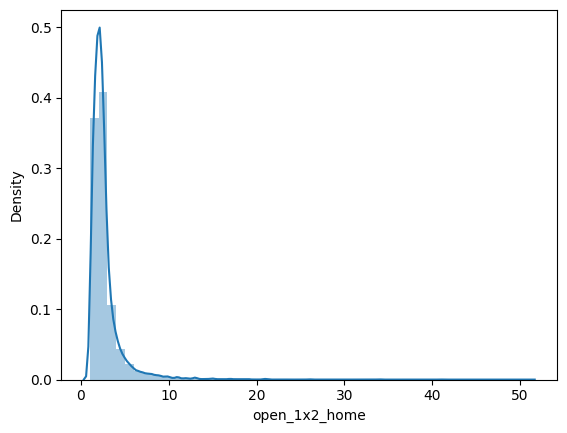

In [17]:
sns.distplot(df['open_1x2_home'])
plt.show()

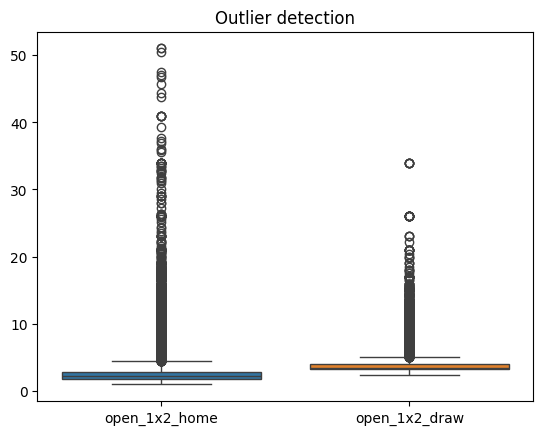

In [18]:
sns.boxplot(df[['open_1x2_home','open_1x2_draw']])
plt.title("Outlier detection")
plt.show()

In [19]:
for col in ['open_1x2_home','open_1x2_draw']:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3-Q1

  lower = Q1-1.5*IQR
  upper = Q3+1.5*IQR

  df[col] = np.where(df[col]>upper,upper,np.where(df[col]<lower,lower,df[col]))

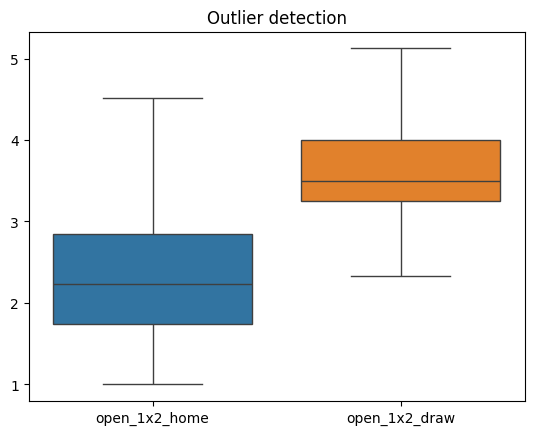

In [20]:
sns.boxplot(df[['open_1x2_home','open_1x2_draw']])
plt.title("Outlier detection")
plt.show()

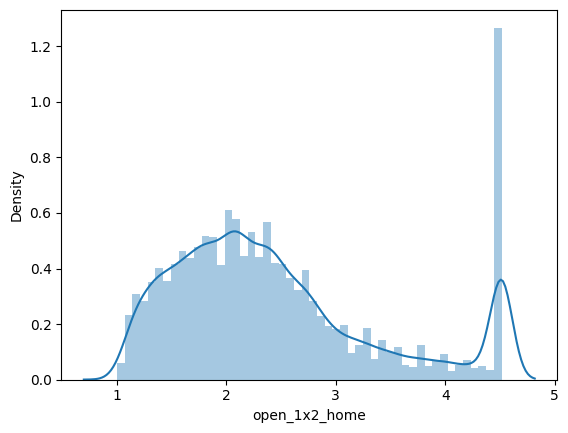

In [21]:
sns.distplot(df['open_1x2_home'])
plt.show()

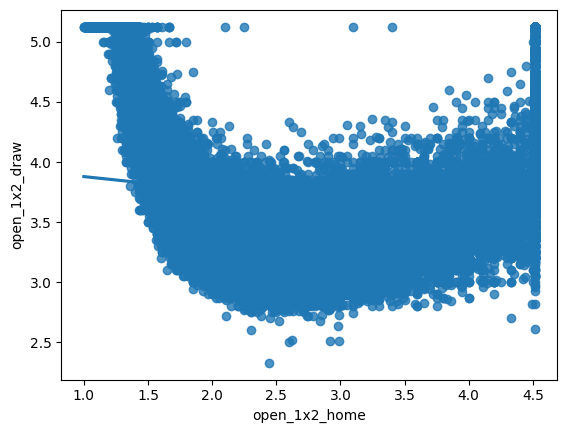

In [22]:
sns.regplot(x=df['open_1x2_home'],y=df['open_1x2_draw'])
plt.show()